# Adaptive LLM Inference Engine using Workload-Aware Scheduling and ML-Based Latency Prediction

## 1. Introduction

Large Language Models (LLMs) are increasingly used in applications such as conversational AI, content generation, question answering, and intelligent assistants.

When multiple users send requests to an LLM inference engine simultaneously, the system must manage request arrivals, waiting queues, processing capacity, and response latency.

Traditional scheduling approaches, such as First-In-First-Out (FIFO), do not consider differences in request sizes or predicted processing times. This can lead to inefficient queue management and increased waiting times under varying workloads.

This project proposes an adaptive LLM inference scheduling framework that combines workload-aware scheduling with Machine Learning-based latency prediction.

A Random Forest Regression model predicts request processing latency using admission-time workload features. The predicted latency is then used by the proposed CAMP scheduler to prioritize requests. Fair-CAMP extends this approach with an aging-based rule to improve waiting-time fairness.

## 2. Project Objectives

1. Study request scheduling challenges in LLM inference systems.
2. Develop a Machine Learning model to predict LLM engine latency.
3. Implement and compare FIFO, Fixed-K, Adaptive, CAMP, and Fair-CAMP scheduling policies.
4. Evaluate scheduler performance using queue waiting time, end-to-end latency, and throughput.
5. Analyze fairness, workload-specific performance, and limitations.

## 3. Project Scope

The project includes latency dataset preparation, Random Forest model training and evaluation, and event-driven simulation of scheduling policies.

**Experimental scope:** Scheduler comparisons are performed using event-driven simulation with predicted service times. They are not measurements of live GPU scheduling performance.

## 4. Problem Statement

LLM inference systems receive requests with different prompt lengths, output requirements, and arrival patterns. When multiple requests arrive simultaneously, limited processing capacity can create waiting queues and increase response latency.

A basic FIFO scheduler processes requests in arrival order without considering their expected processing requirements. Although simple, this approach may not provide efficient scheduling under mixed and bursty workloads.

The problem addressed in this project is:

**How can Machine Learning-based latency prediction and workload-aware scheduling improve request waiting time, end-to-end latency, and fairness in LLM inference workloads?**

### Key Challenges

1. Variable request sizes and processing requirements.
2. Changing request arrival rates.
3. Limited inference concurrency.
4. Increased queue waiting time during bursty workloads.
5. Balancing average latency and tail latency while maintaining fairness.

### Proposed Solution

This project develops a scheduling framework that uses a Random Forest Regression model to predict request processing latency. The predictions guide CAMP scheduling, while Fair-CAMP introduces an aging-based priority rule to reduce excessive waiting by older requests.

## 5. Proposed System Architecture

The proposed system consists of four major stages:

1. **Workload Dataset:** Contains LLM inference requests with prompt length, maximum output tokens, workload type, and arrival information.
2. **ML-Based Latency Predictor:** A trained Random Forest Regression model predicts engine processing latency using admission-time features.
3. **Scheduling Engine:** Five scheduling policies are evaluated:
   - FIFO
   - Fixed-K
   - Adaptive
   - CAMP
   - Fair-CAMP
4. **Performance Evaluation:** Scheduler results are compared using average queue waiting time, P95 queue waiting time, maximum queue waiting time, average end-to-end latency, P95 end-to-end latency, and throughput.

### System Workflow

Workload Dataset → Feature Preparation → Random Forest Latency Prediction → Scheduling Policy → Request Execution Simulation → Performance Evaluation

### Proposed Contribution

The proposed CAMP scheduler uses predicted processing latency to prioritize requests. Fair-CAMP extends CAMP by introducing an aging-based rule that gives priority to older waiting requests after a specified waiting threshold.

The framework evaluates the trade-off between average performance and tail-waiting-time fairness.

## 6. Dataset Description

This project uses two datasets generated during the LLM inference benchmarking process.

### 6.1 Latency Prediction Dataset

File: `latency_dataset_tokenfixed.csv`

- Total records: 180 requests
- Workload types: Steady, Mixed, and Bursty
- Records per workload: 60
- Training records: 120
- Testing records: 60
- Target variable: `engine_latency_s`

The dataset contains request characteristics, workload information, admission-time system features, and measured latency values.

### 6.2 Scheduler Benchmark Dataset

File: `benchmark_traces_tokenfixed.csv`

- Total benchmark requests: 36
- Workload types: Steady, Mixed, and Bursty
- Records per workload: 12

This dataset provides the request arrival information, prompt text, prompt token count, and maximum output token count used in scheduler simulation.

### 6.3 Data Preparation

The latency dataset is divided by experimental run:

- Runs 1 and 2 are used for training.
- Run 3 is reserved for testing.

This run-based split prevents requests from the same experimental run from appearing in both training and testing sets.

Categorical workload information is converted into one-hot encoded features for model training and prediction.

### 6.4 Dataset Limitation

The datasets represent the collected benchmark workload and do not cover every possible LLM model, GPU configuration, or production traffic pattern. Therefore, the findings should be interpreted within the scope of the available experiments.

## 7. Machine Learning Model – Random Forest Regression

A Random Forest Regression model is used to predict LLM engine processing latency.

### 7.1 Model Selection

Random Forest Regression was selected because it can learn nonlinear relationships between request characteristics and processing latency. It also provides feature importance values that help interpret the prediction model.

### 7.2 Input Features

The model uses nine admission-time features:

1. `prompt_tokens`
2. `max_output_tokens`
3. `arrival_rate_5s_rps`
4. `queue_depth_at_admission`
5. `active_requests_at_admission`
6. `concurrency_limit`
7. `workload_type_bursty`
8. `workload_type_mixed`
9. `workload_type_steady`

### 7.3 Prediction Target

The target variable is `engine_latency_s`, representing measured engine processing latency in seconds.

### 7.4 Model Configuration

| Parameter | Value |
|---|---:|
| Model | RandomForestRegressor |
| Number of estimators | 100 |
| Maximum depth | 5 |
| Minimum samples split | 4 |
| Minimum samples leaf | 2 |
| Random state | 42 |

### 7.5 Training and Testing

The dataset contains 180 requests:
- Training: 120 requests from runs 1 and 2.
- Testing: 60 requests from run 3.

The trained model is saved as `camp_latency_predictor.joblib`, and the feature-column order is saved as `camp_feature_columns.joblib`.

## 8. Model Performance Evaluation

The trained Random Forest Regression model is evaluated using three standard regression metrics.

### 8.1 Evaluation Metrics

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted latency.
- **Root Mean Squared Error (RMSE):** Measures prediction error while giving greater weight to larger errors.
- **R² Score:** Measures how much variation in the target variable is explained by the model.

### 8.2 Experimental Results

The model was evaluated on 60 unseen test requests.

| Evaluation Metric | Result |
|---|---:|
| MAE | 0.135079 seconds |
| RMSE | 0.185927 seconds |
| R² Score | 0.72094 |

### 8.3 Result Interpretation

The model achieved an MAE of approximately 0.135 seconds, indicating that its predictions differ from actual engine latency by around 0.135 seconds on average.

The R² score of 0.72094 indicates that the model explains approximately 72.09% of the variation in engine latency on the held-out test set.

These results indicate that the trained model can provide useful latency estimates for the scheduling simulation.

### 8.4 Feature Importance

The most influential features according to the trained Random Forest model are:

| Feature | Importance |
|---|---:|
| max_output_tokens | 83.68% |
| arrival_rate_5s_rps | 6.59% |
| queue_depth_at_admission | 4.90% |
| prompt_tokens | 2.52% |

The requested maximum output length has the highest feature importance in this dataset.

Feature importance represents the model's learned predictive contribution and does not establish a causal relationship.

## 9. Scheduling Algorithms

Five scheduling policies are implemented and compared to evaluate their performance under different LLM request workloads.

### 9.1 FIFO (First-In-First-Out)

Requests are processed in their order of arrival. The scheduler does not consider predicted processing time or request size.

### 9.2 Fixed-K Scheduling

A fixed concurrency limit of K = 4 is used. Requests are admitted for processing when a processing slot becomes available.

### 9.3 Adaptive Scheduling

The concurrency limit changes according to the observed request arrival rate:

- Concurrency limit = 2 when arrival rate is greater than or equal to 2 requests per second.
- Concurrency limit = 4 when arrival rate is below 2 requests per second.

### 9.4 CAMP (Proposed Scheduler)

CAMP uses the Random Forest model's predicted processing latency to prioritize requests.

Requests with shorter predicted processing times are selected before requests with longer predicted processing times. The maximum concurrency limit is 4.

### 9.5 Fair-CAMP (Fairness Extension)

Fair-CAMP extends CAMP with an aging-based priority rule.

When the oldest waiting request has waited for at least 2 seconds, it receives priority over the shortest-predicted-time request.

Otherwise, requests are prioritized using predicted processing time.

This approach aims to reduce excessive waiting for older requests while retaining latency-aware scheduling.

### 9.6 Scheduling Comparison

All five policies are evaluated using the same benchmark request traces and predicted service-time inputs.

The comparison focuses on:

- Average queue waiting time
- P95 queue waiting time
- Maximum queue waiting time
- Average end-to-end latency
- P95 end-to-end latency
- Throughput

## 10. Experimental Setup

The scheduling policies are evaluated using a common benchmark dataset and predicted service-time values.

### 10.1 Experimental Configuration

| Parameter | Configuration |
|---|---|
| Benchmark requests | 36 |
| Workload types | Steady, Mixed, Bursty |
| Requests per workload | 12 |
| Scheduling policies | 5 |
| Fixed concurrency limit | 4 |
| Adaptive concurrency limits | 2 or 4 |
| Fair-CAMP aging threshold | 2 seconds |
| Latency prediction model | Random Forest Regression |

### 10.2 Workload Categories

- **Steady workload:** Represents a relatively regular request arrival pattern.
- **Mixed workload:** Represents a combination of different request arrival patterns.
- **Bursty workload:** Represents periods of concentrated request arrivals.

### 10.3 Evaluation Metrics

The following metrics are used:

1. Average Queue Waiting Time
2. P95 Queue Waiting Time
3. Maximum Queue Waiting Time
4. Average End-to-End Latency
5. P95 End-to-End Latency
6. Throughput in requests per second

### 10.4 Experimental Method

The same 36 benchmark requests and predicted service-time inputs are used to compare all five scheduling policies.

An event-driven simulation calculates request arrival, scheduling, service start, waiting time, and completion time.

This provides a controlled comparison of scheduling strategies without claiming that the simulation reproduces real GPU contention or live inference execution.

## 11. Overall Scheduler Performance Results

The five scheduling policies were evaluated using the same 36 benchmark requests.

### 11.1 Overall Results

| Scheduler | Average Queue Wait (s) | P95 Queue Wait (s) | Max Queue Wait (s) | Average End-to-End (s) | P95 End-to-End (s) | Throughput (req/s) |
|---|---:|---:|---:|---:|---:|---:|
| FIFO | 1.9820 | 3.5751 | 3.8535 | 3.1401 | 4.9982 | 3.3179 |
| Fixed-K | 1.9820 | 3.5751 | 3.8535 | 3.1401 | 4.9982 | 3.3179 |
| Adaptive | 5.3444 | 10.8564 | 11.7712 | 6.5025 | 11.8957 | 1.8649 |
| CAMP | 1.7203 | 6.9367 | 7.5285 | 2.8784 | 8.4436 | 3.3132 |
| Fair-CAMP | 1.8972 | 3.6577 | 3.7676 | 3.0553 | 4.9447 | 3.3100 |

### 11.2 Key Observations

1. **CAMP:** Achieved the lowest average queue waiting time (1.7203 seconds) and average end-to-end latency (2.8784 seconds).
2. **Fair-CAMP:** Achieved the lowest P95 end-to-end latency (4.9447 seconds) and maximum queue waiting time (3.7676 seconds).
3. **FIFO and Fixed-K:** Produced identical results in this experiment because both use the same FIFO ordering and concurrency limit of four.
4. **Adaptive:** Recorded the highest average waiting time and lowest throughput in this experiment.
5. **Throughput:** FIFO, Fixed-K, CAMP, and Fair-CAMP achieved similar throughput.

### 11.3 Interpretation

CAMP improves average latency-related metrics, while Fair-CAMP provides better tail-waiting-time behavior in this experiment.

No single scheduler performs best across every metric. The results demonstrate a trade-off between average performance and tail latency.

These findings apply to the evaluated simulation and benchmark traces; they should not be interpreted as proof of equivalent improvements on a live GPU inference engine.

## 12. Workload-wise Performance Analysis

The scheduling policies were also evaluated separately across steady, mixed, and bursty workloads to understand how workload characteristics affect scheduler performance.

### 12.1 Bursty Workload

- CAMP achieved the lowest average queue wait of 1.6560 seconds.
- CAMP achieved the lowest average end-to-end latency of 2.8508 seconds.
- Fair-CAMP achieved the lowest P95 queue wait of 3.2561 seconds.
- Fair-CAMP achieved the lowest P95 end-to-end latency of 4.5695 seconds.

### 12.2 Mixed Workload

- CAMP achieved the lowest average queue wait of 1.6950 seconds.
- CAMP achieved the lowest average end-to-end latency of 2.8789 seconds.
- Fair-CAMP achieved the lowest P95 queue wait of 3.6295 seconds.
- Fair-CAMP achieved the lowest P95 end-to-end latency of 5.0153 seconds.

### 12.3 Steady Workload

- CAMP achieved the lowest average queue wait of 1.8098 seconds.
- CAMP achieved the lowest average end-to-end latency of 2.9055 seconds.
- FIFO and Fixed-K achieved the lowest P95 queue wait of 3.4990 seconds.
- FIFO and Fixed-K achieved the lowest P95 end-to-end latency of 4.7487 seconds.

### 12.4 Overall Interpretation

CAMP consistently achieved the lowest average queue waiting time and average end-to-end latency across the three workload categories.

Fair-CAMP performed particularly well on tail latency in bursty and mixed workloads. However, FIFO and Fixed-K performed better on P95 end-to-end latency in the steady workload.

Adaptive scheduling recorded comparatively higher latency metrics across all three workload categories in this experiment.

These results indicate that scheduler effectiveness depends on the workload pattern and the performance metric being considered.

## 13. CAMP vs Fair-CAMP: Fairness Analysis

CAMP prioritizes requests using predicted processing latency. This can improve average waiting time, but requests with longer predicted processing times may experience greater waiting times.

Fair-CAMP introduces an aging-based rule. If the oldest waiting request reaches the 2-second threshold, it receives priority over the shortest-predicted-time request.

### 13.1 Comparative Results

| Metric | CAMP | Fair-CAMP |
|---|---:|---:|
| Average Queue Wait (s) | 1.7203 | 1.8972 |
| P95 Queue Wait (s) | 6.9367 | 3.6577 |
| Maximum Queue Wait (s) | 7.5285 | 3.7676 |

### 13.2 Key Observations

1. CAMP achieved lower average queue waiting time.
2. Fair-CAMP reduced P95 queue waiting time compared with CAMP.
3. Fair-CAMP reduced maximum queue waiting time compared with CAMP.
4. Fair-CAMP introduces a trade-off: slightly higher average waiting time in exchange for improved tail-waiting-time behavior.

### 13.3 Interpretation

The results suggest that the aging-based priority rule improves waiting-time fairness in the evaluated simulation.

However, this experiment does not prove that starvation is impossible under every workload. Further testing with larger workloads and different arrival patterns is required.

## 14. Limitations and Responsible AI Considerations

### 14.1 Project Limitations

1. **Limited dataset:** The latency prediction model uses 180 benchmark requests, which may not represent all real-world LLM workloads.
2. **Model dependency:** Prediction accuracy depends on the quality and representativeness of the training data.
3. **Simulation-based evaluation:** Scheduler comparisons use event-driven simulation rather than live GPU scheduling.
4. **Simplified service times:** Predicted service times are treated as fixed values during each simulation. Dynamic GPU contention is not modeled.
5. **Limited workload diversity:** Only steady, mixed, and bursty workload patterns are evaluated.
6. **Adaptive policy limitation:** The selected arrival-rate threshold and concurrency limits are fixed experimental settings, not universally optimal values.

### 14.2 Responsible AI Considerations

- **Transparency:** The scheduling decisions and prediction metrics should be documented clearly.
- **Reliability:** Prediction errors may affect scheduling decisions and should be monitored.
- **Fairness:** The Fair-CAMP aging rule attempts to reduce excessive waiting for older requests.
- **Honest reporting:** Simulated results must not be presented as actual live GPU performance.
- **Reproducibility:** Dataset files, model configuration, evaluation metrics, and experiment outputs should be preserved.

### 14.3 Future Improvements

1. Evaluate the system using larger and more diverse benchmark datasets.
2. Test the scheduler with real concurrent LLM inference requests.
3. Include GPU utilization, memory pressure, and dynamic batching in the scheduling model.
4. Explore online latency prediction and adaptive concurrency control.
5. Evaluate fairness using additional metrics and longer-running workloads.

## 15. Conclusion

This project presented an Adaptive LLM Inference Engine using Workload-Aware Scheduling and Machine Learning-Based Latency Prediction.

A Random Forest Regression model was developed to predict LLM engine processing latency using nine admission-time features. The model achieved an MAE of 0.135079 seconds, RMSE of 0.185927 seconds, and R² score of 0.72094 on the held-out test dataset.

Five scheduling policies—FIFO, Fixed-K, Adaptive, CAMP, and Fair-CAMP—were evaluated using event-driven simulation across steady, mixed, and bursty workloads.

The experimental results showed that:

1. CAMP achieved the lowest average queue waiting time and average end-to-end latency.
2. Fair-CAMP achieved the lowest P95 end-to-end latency and maximum queue waiting time.
3. FIFO and Fixed-K produced identical results under the selected experimental configuration.
4. Adaptive scheduling performed comparatively poorly in the evaluated simulation.

The findings demonstrate the potential of combining Machine Learning-based latency prediction with workload-aware scheduling. They also highlight the trade-off between average latency and tail-waiting-time fairness.

The project provides a foundation for further research involving real-time LLM inference scheduling, dynamic GPU resource management, and larger workload evaluations.

**Final Note:** The scheduler results represent simulation-based comparisons and require validation through real concurrent GPU inference experiments before making production performance claims.

## 16. References

1. Breiman, L. (2001). Random Forests. *Machine Learning, 45*, 5–32.

2. Kingman, J. F. C. (1961). The single server queue in heavy traffic. *Mathematical Proceedings of the Cambridge Philosophical Society*.

3. Harchol-Balter, M. (2013). *Performance Modeling and Design of Computer Systems: Queueing Theory in Action*. Cambridge University Press.

4. Kwon, W., Li, Z., Zhuang, S., et al. (2023). Efficient Memory Management for Large Language Model Serving with PagedAttention. *Proceedings of the ACM Symposium on Operating Systems Principles (SOSP)*.

5. Qwen Team. (2024). Qwen2.5 Technical Report. arXiv.

6. Scikit-learn Developers. RandomForestRegressor Documentation. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

7. vLLM Documentation. https://docs.vllm.ai/

8. Hugging Face. Transformers Documentation. https://huggingface.co/docs/transformers/

9. Project datasets, trained model, and experimental results generated during this project.

## 17. Result Visualization

This section presents graphical comparisons of the five scheduling policies using the experimental results saved in CSV format.

The visualizations help compare average waiting time, tail latency, end-to-end latency, and workload-specific performance.

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nCSV files available here:")

for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current folder: /content

CSV files available here:


In [ ]:
import os

print("Files and folders in /content:")
for item in os.listdir("/content"):
    print(item)

Files and folders in /content:
.config
sample_data


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Adaptive_LLM_Inference_Project_Results.zip to Adaptive_LLM_Inference_Project_Results.zip


In [ ]:
import zipfile
import os

zip_path = "/content/Adaptive_LLM_Inference_Project_Results.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Extraction completed!")
print("\nExtracted files:")

for root, dirs, files_list in os.walk("/content"):
    for file in files_list:
        if file != "Adaptive_LLM_Inference_Project_Results.zip":
            print(os.path.join(root, file))

Extraction completed!

Extracted files:
/content/camp_feature_columns.joblib
/content/camp_fair_camp_fairness_comparison.csv
/content/predictor_test_metrics.csv
/content/corrected_workload_scheduler_comparison.csv
/content/predictor_feature_importance.csv
/content/camp_latency_predictor.joblib
/content/final_experiment_summary.csv
/content/latency_dataset_tokenfixed.csv
/content/corrected_scheduler_comparison.csv
/content/model_metadata.json
/content/benchmark_traces_tokenfixed.csv
/content/predictor_test_predictions.csv
/content/.config/default_configs.db
/content/.config/gce
/content/.config/.last_update_check.json
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/config_sentinel
/content/.config/active_config
/content/.config/.last_survey_prompt.yaml
/content/.config/.last_opt_in_prompt.yaml
/content/.config/logs/2026.10.26/22.18.15.518759.log
/content/.config/logs/2026.10.26/22.18.38.571729.log
/content/.config/logs/2026.10.26/22.18.53

,Scheduler,Average Queue Wait (s)
0,FIFO,1.981971
1,Fixed-K,1.981971
2,Adaptive,5.344386
3,CAMP,1.720310
4,Fair-CAMP,1.897151


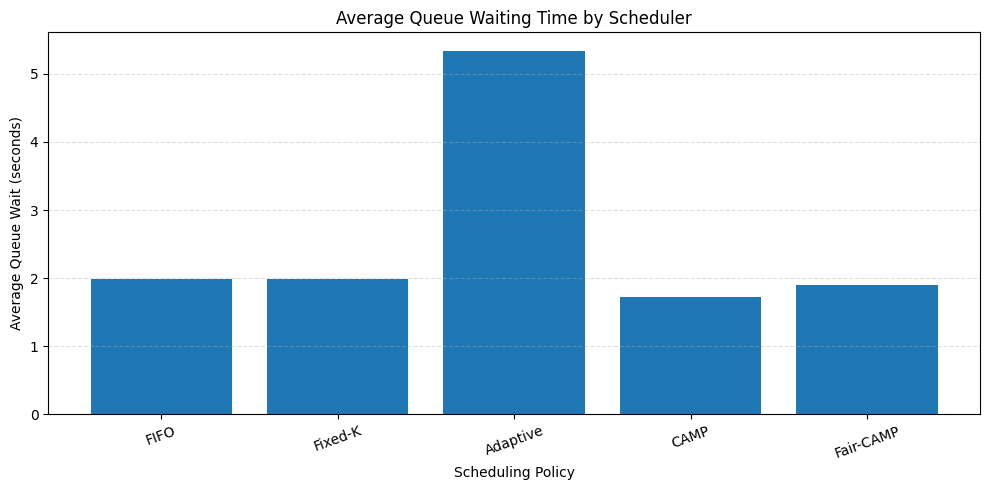

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/corrected_scheduler_comparison.csv")

display(results[["Scheduler", "Average Queue Wait (s)"]])

plt.figure(figsize=(10, 5))
plt.bar(results["Scheduler"], results["Average Queue Wait (s)"])
plt.title("Average Queue Waiting Time by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("Average Queue Wait (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

,Scheduler,P95 End-to-End (s)
0,FIFO,4.998214
1,Fixed-K,4.998214
2,Adaptive,11.895652
3,CAMP,8.443585
4,Fair-CAMP,4.944674


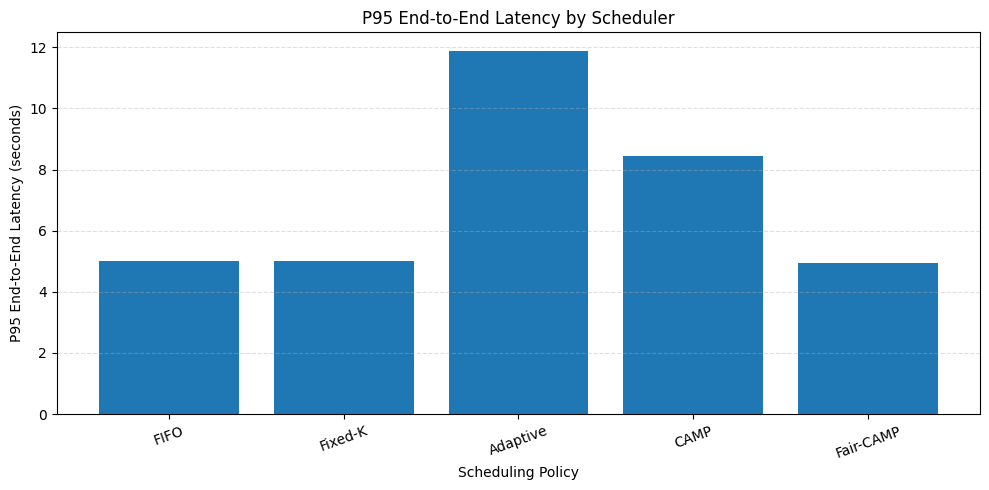

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/corrected_scheduler_comparison.csv")

display(results[["Scheduler", "P95 End-to-End (s)"]])

plt.figure(figsize=(10, 5))
plt.bar(results["Scheduler"], results["P95 End-to-End (s)"])
plt.title("P95 End-to-End Latency by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("P95 End-to-End Latency (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

,Scheduler,Average End-to-End (s)
0,FIFO,3.140092
1,Fixed-K,3.140092
2,Adaptive,6.502507
3,CAMP,2.878431
4,Fair-CAMP,3.055272


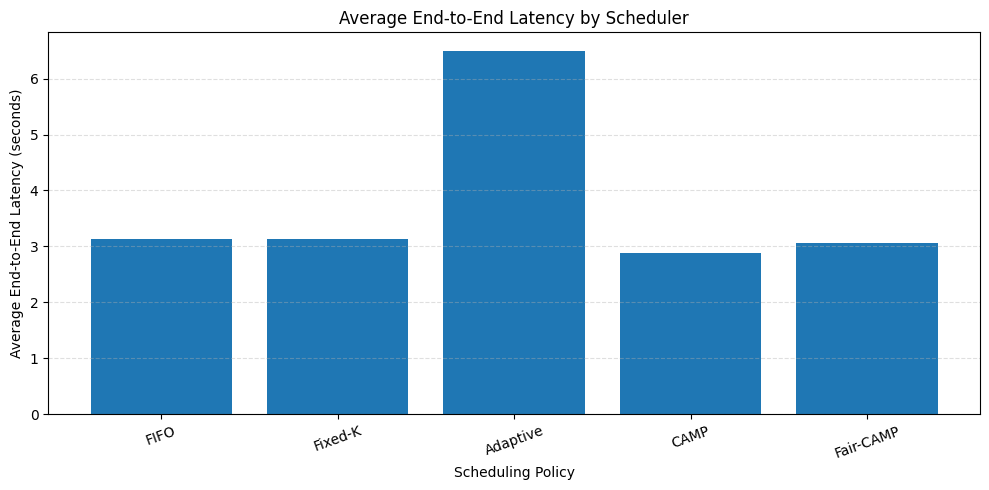

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/corrected_scheduler_comparison.csv")

display(results[["Scheduler", "Average End-to-End (s)"]])

plt.figure(figsize=(10, 5))
plt.bar(results["Scheduler"], results["Average End-to-End (s)"])
plt.title("Average End-to-End Latency by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("Average End-to-End Latency (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


,Scheduler,P95 Queue Wait (s)
0,FIFO,3.575052
1,Fixed-K,3.575052
2,Adaptive,10.856398
3,CAMP,6.936714
4,Fair-CAMP,3.657743


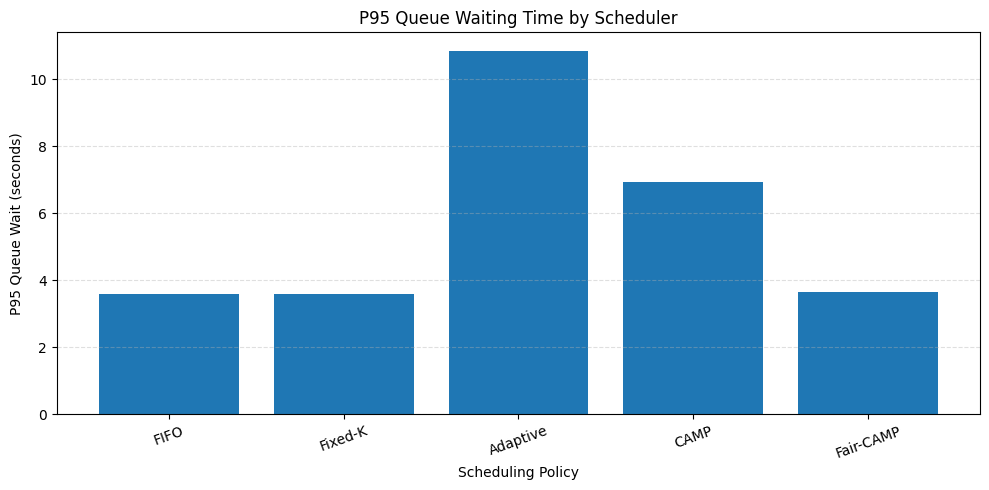

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/corrected_scheduler_comparison.csv")

display(results[["Scheduler", "P95 Queue Wait (s)"]])

plt.figure(figsize=(10, 5))
plt.bar(results["Scheduler"], results["P95 Queue Wait (s)"])
plt.title("P95 Queue Waiting Time by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("P95 Queue Wait (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

results = pd.read_csv("/content/corrected_workload_scheduler_comparison.csv")

print("Available columns:")
print(results.columns.tolist())

print("\nFirst five rows:")
display(results.head())

Available columns:
['Workload', 'Scheduler', 'Average Queue Wait (s)', 'P95 Queue Wait (s)', 'Average End-to-End (s)', 'P95 End-to-End (s)']

First five rows:


,Workload,Scheduler,Average Queue Wait (s),P95 Queue Wait (s),Average End-to-End (s),P95 End-to-End (s)
0,bursty,Adaptive,5.209997,11.046036,6.404791,12.498149
1,bursty,CAMP,1.656037,5.410287,2.850831,6.903476
2,bursty,FIFO,1.895448,3.292854,3.090242,4.652963
3,bursty,Fair-CAMP,1.707663,3.256083,2.902457,4.569454
4,bursty,Fixed-K,1.895448,3.292854,3.090242,4.652963


Workload,bursty,mixed,steady
Scheduler,,,
Adaptive,5.209997,4.012224,6.810937
CAMP,1.656037,1.695044,1.809849
FIFO,1.895448,1.724359,2.326107
Fair-CAMP,1.707663,1.813624,2.170166
Fixed-K,1.895448,1.724359,2.326107


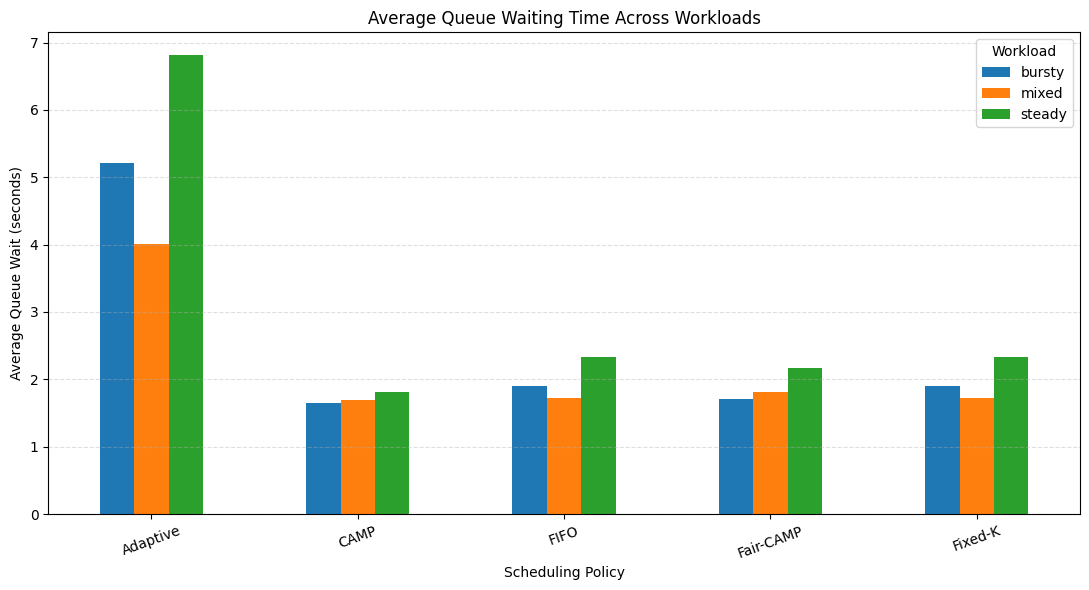

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/corrected_workload_scheduler_comparison.csv")

pivot = results.pivot(
    index="Scheduler",
    columns="Workload",
    values="Average Queue Wait (s)"
)

display(pivot)

pivot.plot(kind="bar", figsize=(11, 6))

plt.title("Average Queue Waiting Time Across Workloads")
plt.xlabel("Scheduling Policy")
plt.ylabel("Average Queue Wait (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Workload")
plt.tight_layout()
plt.show()

Workload,bursty,mixed,steady
Scheduler,,,
Adaptive,12.498149,11.059795,11.898239
CAMP,6.903476,5.749738,8.932436
FIFO,4.652963,5.175748,4.748706
Fair-CAMP,4.569454,5.015287,4.920342
Fixed-K,4.652963,5.175748,4.748706


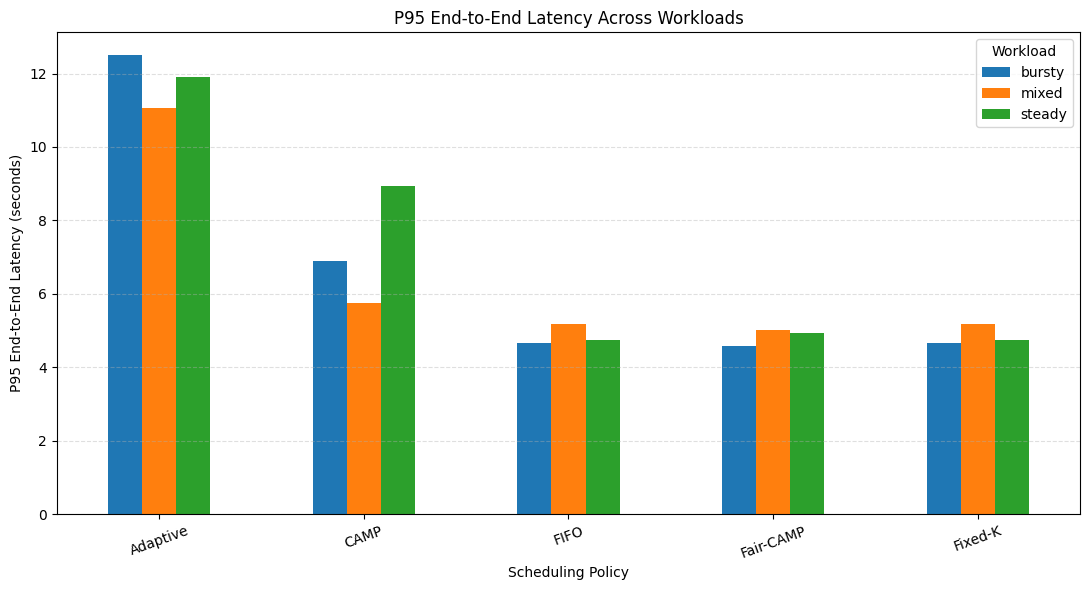

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/corrected_workload_scheduler_comparison.csv")

pivot = results.pivot(
    index="Scheduler",
    columns="Workload",
    values="P95 End-to-End (s)"
)

display(pivot)

pivot.plot(kind="bar", figsize=(11, 6))

plt.title("P95 End-to-End Latency Across Workloads")
plt.xlabel("Scheduling Policy")
plt.ylabel("P95 End-to-End Latency (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Workload")
plt.tight_layout()
plt.show()

,Feature,Importance
0,max_output_tokens,0.836778
1,arrival_rate_5s_rps,0.065876
2,queue_depth_at_admission,0.048998
3,prompt_tokens,0.025231
4,active_requests_at_admission,0.010450
5,workload_type_mixed,0.005279
6,workload_type_bursty,0.003241
7,workload_type_steady,0.002912
8,concurrency_limit,0.001235


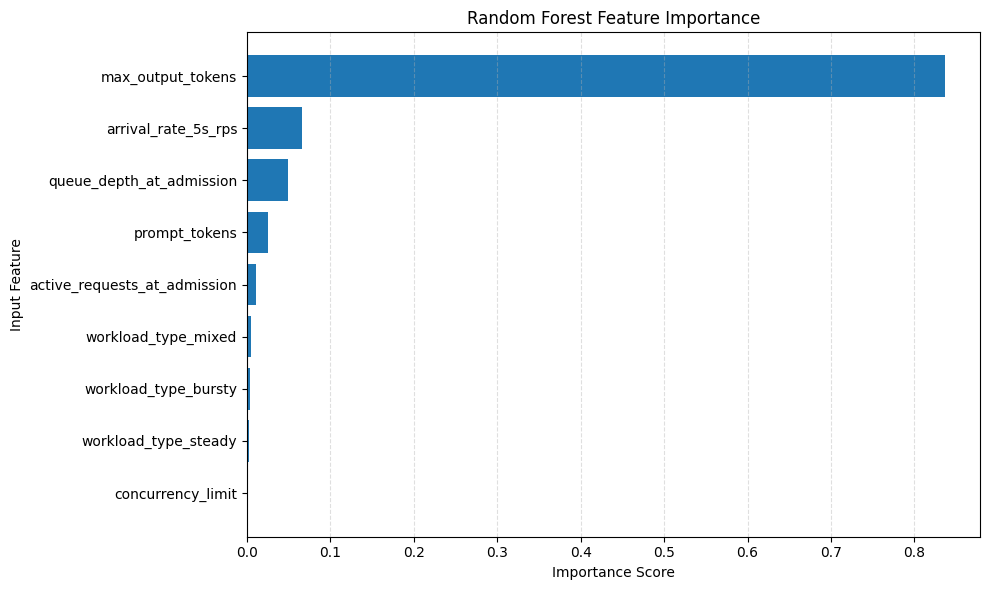

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.read_csv("/content/predictor_feature_importance.csv")

display(importance)

plt.figure(figsize=(10, 6))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

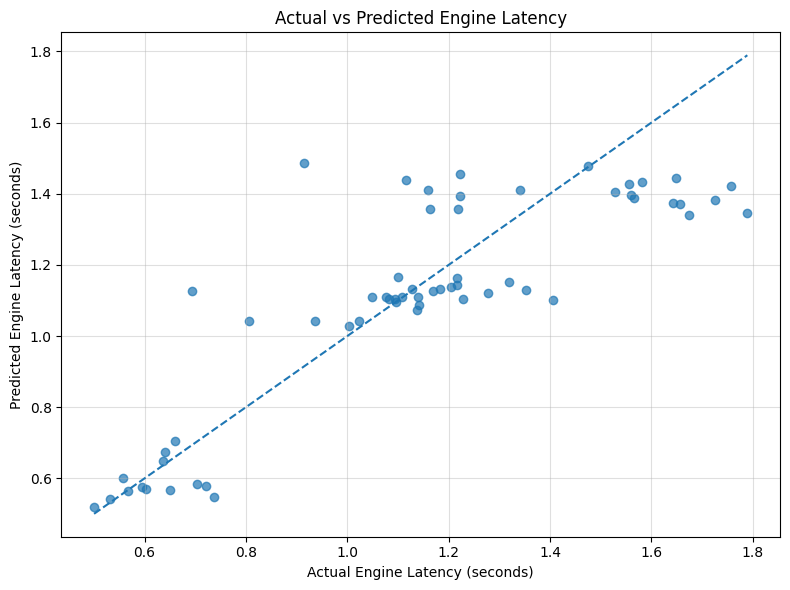

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

predictions = pd.read_csv("/content/predictor_test_predictions.csv")

plt.figure(figsize=(8, 6))

plt.scatter(
    predictions["actual_engine_latency_s"],
    predictions["predicted_engine_latency_s"],
    alpha=0.7
)

# Ideal prediction reference line
min_value = min(
    predictions["actual_engine_latency_s"].min(),
    predictions["predicted_engine_latency_s"].min()
)
max_value = max(
    predictions["actual_engine_latency_s"].max(),
    predictions["predicted_engine_latency_s"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Engine Latency")
plt.xlabel("Actual Engine Latency (seconds)")
plt.ylabel("Predicted Engine Latency (seconds)")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:

import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

# Create folder for all graphs
output_dir = "/content/Project_Graphs"
os.makedirs(output_dir, exist_ok=True)

# Load project results
overall = pd.read_csv("/content/corrected_scheduler_comparison.csv")
workload = pd.read_csv("/content/corrected_workload_scheduler_comparison.csv")
importance = pd.read_csv("/content/predictor_feature_importance.csv")
predictions = pd.read_csv("/content/predictor_test_predictions.csv")

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()
    print("Saved:", filename)

# 1. Average Queue Waiting Time
plt.figure(figsize=(10, 5))
plt.bar(overall["Scheduler"], overall["Average Queue Wait (s)"])
plt.title("Average Queue Waiting Time by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("Average Queue Wait (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
save_plot("01_average_queue_wait.png")

# 2. P95 End-to-End Latency
plt.figure(figsize=(10, 5))
plt.bar(overall["Scheduler"], overall["P95 End-to-End (s)"])
plt.title("P95 End-to-End Latency by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("P95 Latency (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
save_plot("02_p95_end_to_end_latency.png")

# 3. Average End-to-End Latency
plt.figure(figsize=(10, 5))
plt.bar(overall["Scheduler"], overall["Average End-to-End (s)"])
plt.title("Average End-to-End Latency by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("Average Latency (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
save_plot("03_average_end_to_end_latency.png")

# 4. P95 Queue Waiting Time
plt.figure(figsize=(10, 5))
plt.bar(overall["Scheduler"], overall["P95 Queue Wait (s)"])
plt.title("P95 Queue Waiting Time by Scheduler")
plt.xlabel("Scheduling Policy")
plt.ylabel("P95 Queue Wait (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
save_plot("04_p95_queue_wait.png")

# 5. Workload-wise Average Queue Waiting Time
pivot = workload.pivot(
    index="Scheduler",
    columns="Workload",
    values="Average Queue Wait (s)"
)
pivot.plot(kind="bar", figsize=(11, 6))
plt.title("Average Queue Waiting Time Across Workloads")
plt.xlabel("Scheduling Policy")
plt.ylabel("Average Queue Wait (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
plt.legend(title="Workload")
save_plot("05_workload_average_queue_wait.png")

# 6. Workload-wise P95 End-to-End Latency
pivot = workload.pivot(
    index="Scheduler",
    columns="Workload",
    values="P95 End-to-End (s)"
)
pivot.plot(kind="bar", figsize=(11, 6))
plt.title("P95 End-to-End Latency Across Workloads")
plt.xlabel("Scheduling Policy")
plt.ylabel("P95 Latency (seconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
plt.legend(title="Workload")
save_plot("06_workload_p95_latency.png")

# 7. Random Forest Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.4)
save_plot("07_random_forest_feature_importance.png")

# 8. Actual vs Predicted Engine Latency
plt.figure(figsize=(8, 6))
plt.scatter(
    predictions["actual_engine_latency_s"],
    predictions["predicted_engine_latency_s"],
    alpha=0.7
)

min_value = min(
    predictions["actual_engine_latency_s"].min(),
    predictions["predicted_engine_latency_s"].min()
)
max_value = max(
    predictions["actual_engine_latency_s"].max(),
    predictions["predicted_engine_latency_s"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)
plt.title("Actual vs Predicted Engine Latency")
plt.xlabel("Actual Latency (seconds)")
plt.ylabel("Predicted Latency (seconds)")
plt.grid(alpha=0.4)
save_plot("08_actual_vs_predicted_latency.png")

# Package all eight images into a ZIP file
zip_path = "/content/Project_Graphs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for filename in sorted(os.listdir(output_dir)):
        zip_file.write(
            os.path.join(output_dir, filename),
            arcname=filename
        )

print("\nSUCCESS: All eight graphs have been saved!")
print("ZIP file:", zip_path)

# Download the ZIP file
from google.colab import files
files.download(zip_path)


Saved: 01_average_queue_wait.png
Saved: 02_p95_end_to_end_latency.png
Saved: 03_average_end_to_end_latency.png
Saved: 04_p95_queue_wait.png
Saved: 05_workload_average_queue_wait.png
Saved: 06_workload_p95_latency.png
Saved: 07_random_forest_feature_importance.png
Saved: 08_actual_vs_predicted_latency.png

SUCCESS: All eight graphs have been saved!
ZIP file: /content/Project_Graphs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

predictions = pd.read_csv("/content/predictor_test_predictions.csv")

print("Available columns:")
print(predictions.columns.tolist())

display(predictions.head())


Available columns:
['request_id', 'run_id', 'workload_type', 'actual_engine_latency_s', 'predicted_engine_latency_s', 'absolute_error_s']


,request_id,run_id,workload_type,actual_engine_latency_s,predicted_engine_latency_s,absolute_error_s
0,steady_run_3_req_0000,steady_run_3,steady,1.181931,1.132594,0.049338
1,steady_run_3_req_0001,steady_run_3,steady,0.594497,0.574473,0.020025
2,steady_run_3_req_0002,steady_run_3,steady,0.500481,0.518816,0.018335
3,steady_run_3_req_0003,steady_run_3,steady,1.003747,1.028995,0.025248
4,steady_run_3_req_0004,steady_run_3,steady,1.159756,1.411521,0.251765


In [ ]:
import sys
import platform
import pandas as pd
import numpy as np
import sklearn
import matplotlib

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch: Not installed")

try:
    import transformers
    print("Transformers:", transformers.__version__)
except ImportError:
    print("Transformers: Not installed")

try:
    import vllm
    print("vLLM:", vllm.__version__)
except ImportError:
    print("vLLM: Not installed")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
PyTorch: 2.14.1+cpu
CUDA available: False
Transformers: 5.22.1
vLLM: Not installed
